In [1]:
# ============================================================
# GENEFORMER: 14-CLASS CANCER CLASSIFICATION
# Logistic Regression + Deep MLP
# ============================================================

import os
import copy
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

# ============================================================
# 1. CONFIGURATION AND PATHS
# ============================================================

N_Gens = 4096
RANDOM_STATE = 42

# IMPORTANT:
# These files must correspond to the 14-class split.
EMBEDDING_DIR = Path(
    r"F:\GeneformerProject\data\geneformer_embeddings\Third_Strategy\preprocessed_14_cancers"
)

RESULTS_DIR = (
    Path(r"F:\GeneformerProject\results\Third_Strategy\preprocessed_14_cancers")
    / f"Results_{N_Gens}"
)

LR_DIR = RESULTS_DIR / "logistic_regression"
DNN_DIR = RESULTS_DIR / "deep_mlp"

for directory in [RESULTS_DIR, LR_DIR, DNN_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Embedding directory:", EMBEDDING_DIR)
print("Results directory:", RESULTS_DIR)

# ============================================================
# 2. RANDOM SEED AND DEVICE
# ============================================================

np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 75)
print("GENEFORMER 14-CLASS CANCER CLASSIFICATION")
print("=" * 75)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ============================================================
# 3. CANCER CLASS ORDER
# ============================================================

# This order must match the integer encoding used when
# the embedding label files were created.

cancer_codes = [
    "BLCA",
    "BRCA",
    "COAD",
    "GBM",
    "HNSC",
    "KIRC",
    "LAML",
    "LGG",
    "LIHC",
    "LUAD",
    "LUSC",
    "OV",
    "SKCM",
    "STAD"
]

cancer_names = [
    "Bladder urothelial carcinoma",
    "Breast invasive carcinoma",
    "Colon adenocarcinoma",
    "Glioblastoma multiforme",
    "Head and neck squamous cell carcinoma",
    "Kidney renal clear cell carcinoma",
    "Acute myeloid leukemia",
    "Brain lower grade glioma",
    "Liver hepatocellular carcinoma",
    "Lung adenocarcinoma",
    "Lung squamous cell carcinoma",
    "Ovarian serous cystadenocarcinoma",
    "Skin cutaneous melanoma",
    "Stomach adenocarcinoma"
]

NUM_CLASSES = len(cancer_codes)

assert NUM_CLASSES == 14

id_to_cancer = dict(enumerate(cancer_names))

print("\nCancer class mapping:")
for i, (code, name) in enumerate(zip(cancer_codes, cancer_names)):
    print(f"{i}: {code} - {name}")

Embedding directory: F:\GeneformerProject\data\geneformer_embeddings\Third_Strategy\preprocessed_14_cancers
Results directory: F:\GeneformerProject\results\Third_Strategy\preprocessed_14_cancers\Results_4096
GENEFORMER 14-CLASS CANCER CLASSIFICATION
Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU

Cancer class mapping:
0: BLCA - Bladder urothelial carcinoma
1: BRCA - Breast invasive carcinoma
2: COAD - Colon adenocarcinoma
3: GBM - Glioblastoma multiforme
4: HNSC - Head and neck squamous cell carcinoma
5: KIRC - Kidney renal clear cell carcinoma
6: LAML - Acute myeloid leukemia
7: LGG - Brain lower grade glioma
8: LIHC - Liver hepatocellular carcinoma
9: LUAD - Lung adenocarcinoma
10: LUSC - Lung squamous cell carcinoma
11: OV - Ovarian serous cystadenocarcinoma
12: SKCM - Skin cutaneous melanoma
13: STAD - Stomach adenocarcinoma


In [2]:

# ============================================================
# 4. LOAD EMBEDDINGS
# ============================================================

def load_array(filename):
    path = EMBEDDING_DIR / filename

    if not path.exists():
        raise FileNotFoundError(
            f"Required file not found: {path}\n"
            "Check that the 14-class embeddings and labels "
            "have been generated and saved in EMBEDDING_DIR."
        )

    return np.load(path, allow_pickle=False)


X_train = load_array(f"train{N_Gens}_embeddings.npy")
X_val = load_array(f"validation{N_Gens}_embeddings.npy")
X_test = load_array(f"test{N_Gens}_embeddings.npy")

y_train = load_array(f"train{N_Gens}_labels.npy").reshape(-1)
y_val = load_array(f"validation{N_Gens}_labels.npy").reshape(-1)
y_test = load_array(f"test{N_Gens}_labels.npy").reshape(-1)

# ============================================================
# 5. DATA VALIDATION
# ============================================================

print("\n" + "=" * 75)
print("DATA VALIDATION")
print("=" * 75)

for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(f"\n{name}")
    print("Embeddings:", X.shape)
    print("Labels:", y.shape)
    print("Classes:", np.unique(y))

    assert X.ndim == 2, f"{name}: embeddings must be 2D."
    assert len(X) == len(y), f"{name}: embedding/label mismatch."
    assert np.isfinite(X).all(), f"{name}: embeddings contain NaN or Inf."

    if not np.issubdtype(y.dtype, np.integer):
        raise ValueError(
            f"{name}: labels must be integer-encoded "
            "from 0 to 13."
        )

    if not np.array_equal(np.unique(y), np.arange(NUM_CLASSES)):
        raise ValueError(
            f"{name}: expected all labels 0-13. "
            f"Found {np.unique(y)}. Check your label encoding."
        )

INPUT_DIM = X_train.shape[1]

assert INPUT_DIM == 768, (
    f"Expected 768-dimensional Geneformer embeddings; "
    f"found {INPUT_DIM}."
)

assert X_val.shape[1] == INPUT_DIM
assert X_test.shape[1] == INPUT_DIM

print("\nInput dimension:", INPUT_DIM)
print("Number of classes:", NUM_CLASSES)

# Save the explicit label mapping.
with open(RESULTS_DIR / "class_mapping.json", "w") as f:
    json.dump(
        {
            str(i): {
                "code": cancer_codes[i],
                "name": cancer_names[i]
            }
            for i in range(NUM_CLASSES)
        },
        f,
        indent=4
    )

# ============================================================
# 6. CLASS DISTRIBUTION
# ============================================================

for split_name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{split_name} class distribution:")

    counts = pd.Series(labels).value_counts().reindex(
        range(NUM_CLASSES), fill_value=0
    )

    for class_id, count in counts.items():
        print(
            f"{cancer_codes[class_id]:5s} "
            f"{cancer_names[class_id]:45s} "
            f"{count}"
        )

# ============================================================
# 7. EVALUATION FUNCTION
# ============================================================

def calculate_metrics(y_true, y_pred, y_proba):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Macro_Precision": precision_score(
            y_true, y_pred,
            labels=np.arange(NUM_CLASSES),
            average="macro",
            zero_division=0
        ),

        "Weighted_Precision": precision_score(
            y_true, y_pred,
            labels=np.arange(NUM_CLASSES),
            average="weighted",
            zero_division=0
        ),

        "Macro_Recall": recall_score(
            y_true, y_pred,
            labels=np.arange(NUM_CLASSES),
            average="macro",
            zero_division=0
        ),

        "Weighted_Recall": recall_score(
            y_true, y_pred,
            labels=np.arange(NUM_CLASSES),
            average="weighted",
            zero_division=0
        ),

        "Macro_F1": f1_score(
            y_true, y_pred,
            labels=np.arange(NUM_CLASSES),
            average="macro",
            zero_division=0
        ),

        "Weighted_F1": f1_score(
            y_true, y_pred,
            labels=np.arange(NUM_CLASSES),
            average="weighted",
            zero_division=0
        ),

        "Macro_AUC": roc_auc_score(
            y_true, y_proba,
            labels=np.arange(NUM_CLASSES),
            multi_class="ovr",
            average="macro"
        ),

        "Weighted_AUC": roc_auc_score(
            y_true, y_proba,
            labels=np.arange(NUM_CLASSES),
            multi_class="ovr",
            average="weighted"
        )
    }


# ============================================================
# 8. COMMON EVALUATION AND SAVING
# ============================================================

def evaluate_and_save(
    model_name,
    y_true,
    y_pred,
    y_proba,
    output_dir
):
    output_dir = Path(output_dir)

    metrics = calculate_metrics(y_true, y_pred, y_proba)

    print(f"\n{model_name} TEST RESULTS")
    for key, value in metrics.items():
        print(f"{key:22s}: {value:.6f}")

    pd.DataFrame([metrics]).to_csv(
        output_dir / f"{model_name}_test_metrics.csv",
        index=False
    )

    # Per-class classification report
    report = classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=cancer_names,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    # Add TCGA code to individual class rows.
    report_df["TCGA_Code"] = [
        cancer_codes[cancer_names.index(idx)]
        if idx in cancer_names else ""
        for idx in report_df.index
    ]

    report_df.to_csv(
        output_dir / f"{model_name}_classification_report.csv"
    )

    # Confusion matrix
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    pd.DataFrame(
        cm,
        index=cancer_codes,
        columns=cancer_codes
    ).to_csv(
        output_dir / f"{model_name}_confusion_matrix.csv"
    )

    # Per-class one-vs-rest accuracy
    total = cm.sum()
    tp = np.diag(cm)
    fn = cm.sum(axis=1) - tp
    fp = cm.sum(axis=0) - tp
    tn = total - tp - fn - fp

    per_class_acc = (tp + tn) / total

    per_class_df = pd.DataFrame({
        "Class_ID": np.arange(NUM_CLASSES),
        "TCGA_Code": cancer_codes,
        "Cancer_Type": cancer_names,
        "Support": cm.sum(axis=1),
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "One_vs_Rest_Accuracy": per_class_acc
    })

    per_class_df.to_csv(
        output_dir / f"{model_name}_per_class_accuracy.csv",
        index=False
    )

    # Per-class one-vs-rest AUC
    per_class_auc = roc_auc_score(
        y_true,
        y_proba,
        labels=np.arange(NUM_CLASSES),
        multi_class="ovr",
        average=None
    )

    pd.DataFrame({
        "Class_ID": np.arange(NUM_CLASSES),
        "TCGA_Code": cancer_codes,
        "Cancer_Type": cancer_names,
        "AUC": per_class_auc
    }).to_csv(
        output_dir / f"{model_name}_per_class_auc.csv",
        index=False
    )

    # Predictions and probabilities
    prediction_df = pd.DataFrame({
        "True_Label": y_true,
        "True_Code": [cancer_codes[i] for i in y_true],
        "True_Cancer": [cancer_names[i] for i in y_true],
        "Predicted_Label": y_pred,
        "Predicted_Code": [cancer_codes[i] for i in y_pred],
        "Predicted_Cancer": [cancer_names[i] for i in y_pred]
    })

    prediction_df.to_csv(
        output_dir / f"{model_name}_test_predictions.csv",
        index=False
    )

    probability_df = pd.DataFrame(
        y_proba,
        columns=[
            f"Prob_{cancer_codes[i]}_{cancer_names[i]}"
            for i in range(NUM_CLASSES)
        ]
    )

    probability_df.to_csv(
        output_dir / f"{model_name}_test_probabilities.csv",
        index=False
    )

    return metrics, cm


# ============================================================
# 9. STANDARDIZE EMBEDDINGS
# ============================================================

print("\n" + "=" * 75)
print("STANDARDIZATION")
print("=" * 75)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

joblib.dump(scaler, RESULTS_DIR / "embedding_scaler.pkl")

print("Scaler fitted on training data only.")



DATA VALIDATION

Train
Embeddings: (4879, 768)
Labels: (4879,)
Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

Validation
Embeddings: (1046, 768)
Labels: (1046,)
Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

Test
Embeddings: (1046, 768)
Labels: (1046,)
Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13]

Input dimension: 768
Number of classes: 14

Train class distribution:
BLCA  Bladder urothelial carcinoma                  299
BRCA  Breast invasive carcinoma                     853
COAD  Colon adenocarcinoma                          346
GBM   Glioblastoma multiforme                       120
HNSC  Head and neck squamous cell carcinoma         396
KIRC  Kidney renal clear cell carcinoma             424
LAML  Acute myeloid leukemia                        121
LGG   Brain lower grade glioma                      371
LIHC  Liver hepatocellular carcinoma                296
LUAD  Lung adenocarcinoma                           403
LUSC  Lung squamous cell carcinoma              

In [3]:
# ============================================================
# 10. MODEL 1: LOGISTIC REGRESSION
# ============================================================

print("\n" + "=" * 75)
print("MODEL 1: LOGISTIC REGRESSION")
print("=" * 75)

logreg = LogisticRegression(
    C=1.0,
    max_iter=2000,
    solver="lbfgs",
    random_state=RANDOM_STATE
)

logreg.fit(X_train_scaled, y_train)

# Ensure probability columns are ordered 0, 1, ..., 13.
assert np.array_equal(logreg.classes_, np.arange(NUM_CLASSES))

lr_train_pred = logreg.predict(X_train_scaled)
lr_val_pred = logreg.predict(X_val_scaled)
lr_test_pred = logreg.predict(X_test_scaled)

lr_train_proba = logreg.predict_proba(X_train_scaled)
lr_val_proba = logreg.predict_proba(X_val_scaled)
lr_test_proba = logreg.predict_proba(X_test_scaled)

lr_train_metrics = calculate_metrics(
    y_train, lr_train_pred, lr_train_proba
)

lr_val_metrics = calculate_metrics(
    y_val, lr_val_pred, lr_val_proba
)

lr_test_metrics, lr_cm = evaluate_and_save(
    "logistic_regression",
    y_test,
    lr_test_pred,
    lr_test_proba,
    LR_DIR
)

lr_summary = pd.DataFrame([
    {"Model": "Logistic Regression", "Dataset": "Train",
     **lr_train_metrics},
    {"Model": "Logistic Regression", "Dataset": "Validation",
     **lr_val_metrics},
    {"Model": "Logistic Regression", "Dataset": "Test",
     **lr_test_metrics}
])

lr_summary.to_csv(
    LR_DIR / "logistic_regression_results.csv",
    index=False
)

joblib.dump(
    logreg,
    LR_DIR / "logistic_regression_model.pkl"
)



MODEL 1: LOGISTIC REGRESSION

logistic_regression TEST RESULTS
Accuracy              : 0.964627
Macro_Precision       : 0.961980
Weighted_Precision    : 0.965245
Macro_Recall          : 0.963924
Weighted_Recall       : 0.964627
Macro_F1              : 0.962821
Weighted_F1           : 0.964811
Macro_AUC             : 0.999133
Weighted_AUC          : 0.999086


['F:\\GeneformerProject\\results\\Third_Strategy\\preprocessed_14_cancers\\Results_4096\\logistic_regression\\logistic_regression_model.pkl']


Deep MLP architecture:
DeepMLP(
  (network): Sequential(
    (0): Linear(in_features=768, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.5, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.5, inplace=False)
    (12): Linear(in_features=128, out_features=64, bias=True)
    (13): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
    (15): Dropout(p=0.5, inplace=False)
    (16): Linear(in_features=64, out_features=14, bias=True)
  )
)
Total parameters: 569038
Trainable paramete

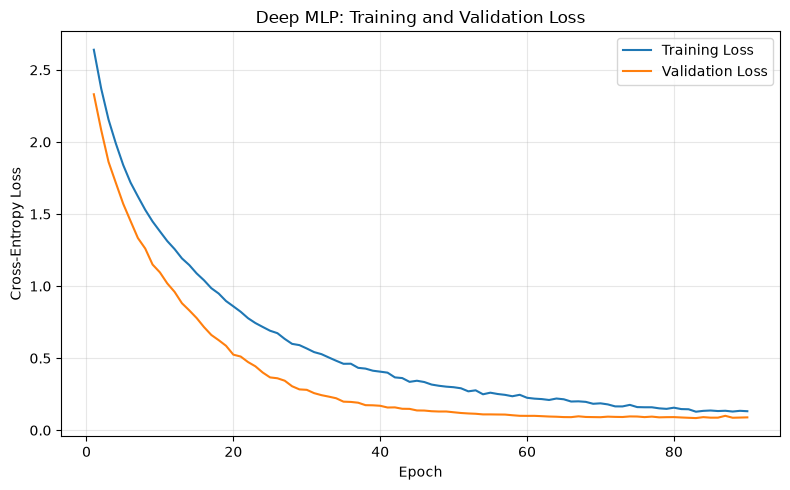

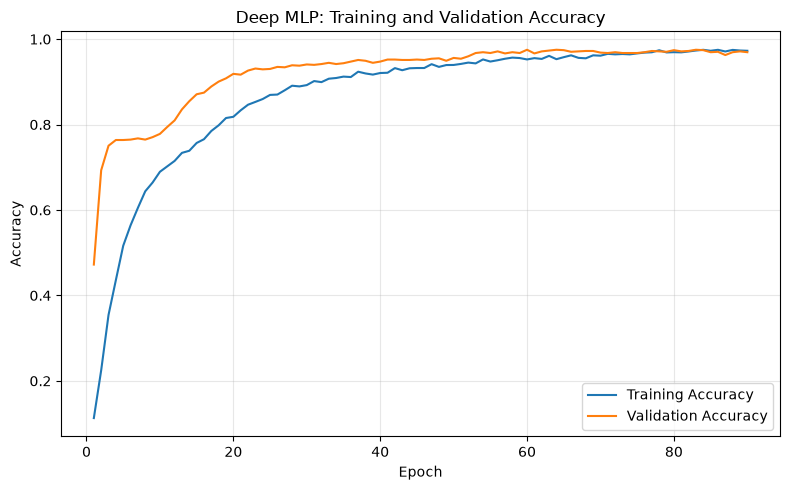

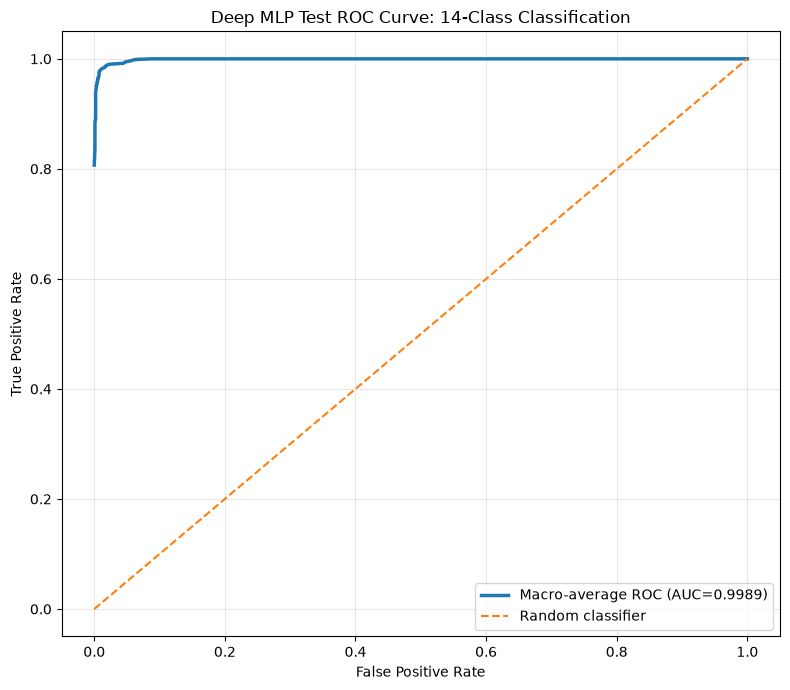


FINAL 14-CLASS TEST COMPARISON
              Model  Accuracy  Macro_Precision  Weighted_Precision  Macro_Recall  Weighted_Recall  Macro_F1  Weighted_F1  Macro_AUC  Weighted_AUC
Logistic Regression    0.9646           0.9620              0.9652        0.9639           0.9646    0.9628       0.9648     0.9991        0.9991
           Deep MLP    0.9656           0.9627              0.9656        0.9594           0.9656    0.9607       0.9654     0.9989        0.9990

EXPERIMENT COMPLETED
Number of classes: 14
Class codes: BLCA, BRCA, COAD, GBM, HNSC, KIRC, LAML, LGG, LIHC, LUAD, LUSC, OV, SKCM, STAD
Embedding dimension: 768
Best epoch: 60
Best validation Macro-F1: 0.973601

Results directory:
F:\GeneformerProject\results\Third_Strategy\preprocessed_14_cancers\Results_4096

Logistic Regression results:
F:\GeneformerProject\results\Third_Strategy\preprocessed_14_cancers\Results_4096\logistic_regression

Deep MLP results:
F:\GeneformerProject\results\Third_Strategy\preprocessed_14_cancers\

In [4]:

# ============================================================
# 11. MODEL 2: DEEP MLP SETTINGS
# ============================================================

BATCH_SIZE = 64
LEARNING_RATE = 7e-5
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 500
DROPOUT = 0.50
PATIENCE = 30

# ============================================================
# 12. PYTORCH TENSORS AND DATALOADER
# ============================================================

X_train_tensor = torch.tensor(
    X_train_scaled, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train, dtype=torch.long
)

X_val_tensor = torch.tensor(
    X_val_scaled, dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val, dtype=torch.long
)

X_test_tensor = torch.tensor(
    X_test_scaled, dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test, dtype=torch.long
)

train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# ============================================================
# 13. DEEP MLP ARCHITECTURE
# ============================================================

class DeepMLP(nn.Module):

    def __init__(
        self,
        input_dim=768,
        num_classes=14,
        dropout=0.50
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.network(x)


deep_mlp = DeepMLP(
    input_dim=INPUT_DIM,
    num_classes=NUM_CLASSES,
    dropout=DROPOUT
).to(device)

print("\nDeep MLP architecture:")
print(deep_mlp)

total_parameters = sum(
    p.numel() for p in deep_mlp.parameters()
)

trainable_parameters = sum(
    p.numel() for p in deep_mlp.parameters()
    if p.requires_grad
)

print("Total parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

with open(DNN_DIR / "deep_mlp_architecture.txt", "w") as f:
    f.write(str(deep_mlp))
    f.write(f"\nInput dimension: {INPUT_DIM}")
    f.write(f"\nNumber of classes: {NUM_CLASSES}")
    f.write(f"\nDropout: {DROPOUT}")
    f.write(f"\nBatch size: {BATCH_SIZE}")
    f.write(f"\nLearning rate: {LEARNING_RATE}")
    f.write(f"\nWeight decay: {WEIGHT_DECAY}")
    f.write(f"\nMaximum epochs: {MAX_EPOCHS}")
    f.write(f"\nEarly stopping patience: {PATIENCE}")
    f.write(f"\nTotal parameters: {total_parameters}")
    f.write(f"\nTrainable parameters: {trainable_parameters}")

# ============================================================
# 14. LOSS AND OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    deep_mlp.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ============================================================
# 15. TRAINING WITH EARLY STOPPING
# ============================================================

best_val_f1 = -np.inf
best_state = None
best_epoch = 0
epochs_without_improvement = 0
history = []

print("\n" + "=" * 75)
print("TRAINING DEEP MLP")
print("=" * 75)

for epoch in range(MAX_EPOCHS):

    # ---------------- TRAIN ----------------
    deep_mlp.train()

    epoch_loss = 0.0
    train_preds = []
    train_true = []

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        logits = deep_mlp(X_batch)
        loss = criterion(logits, y_batch)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

        predictions = torch.argmax(logits, dim=1)

        train_preds.extend(
            predictions.detach().cpu().numpy()
        )

        train_true.extend(
            y_batch.detach().cpu().numpy()
        )

    train_loss = epoch_loss / len(train_loader)

    train_accuracy = accuracy_score(
        train_true, train_preds
    )

    train_f1 = f1_score(
        train_true, train_preds,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0
    )

    # ---------------- VALIDATION ----------------
    deep_mlp.eval()

    with torch.no_grad():

        val_logits = deep_mlp(
            X_val_tensor.to(device)
        )

        val_loss = criterion(
            val_logits,
            y_val_tensor.to(device)
        ).item()

        val_proba = torch.softmax(
            val_logits, dim=1
        ).cpu().numpy()

    val_pred = np.argmax(val_proba, axis=1)

    val_accuracy = accuracy_score(y_val, val_pred)

    val_f1 = f1_score(
        y_val, val_pred,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0
    )

    val_weighted_f1 = f1_score(
        y_val, val_pred,
        labels=np.arange(NUM_CLASSES),
        average="weighted",
        zero_division=0
    )

    history.append({
        "Epoch": epoch + 1,
        "Train_Loss": train_loss,
        "Train_Accuracy": train_accuracy,
        "Train_Macro_F1": train_f1,
        "Val_Loss": val_loss,
        "Val_Accuracy": val_accuracy,
        "Val_Macro_F1": val_f1,
        "Val_Weighted_F1": val_weighted_f1
    })

    # ---------------- BEST MODEL ----------------
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch + 1

        best_state = copy.deepcopy(
            deep_mlp.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch + 1:03d} | "
        f"Train Loss={train_loss:.4f} | "
        f"Train Acc={train_accuracy:.4f} | "
        f"Val Loss={val_loss:.4f} | "
        f"Val Acc={val_accuracy:.4f} | "
        f"Val Macro-F1={val_f1:.4f}"
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch + 1}")
        break

if best_state is None:
    raise RuntimeError("Training did not produce a valid model.")

# Restore best validation Macro-F1 checkpoint
deep_mlp.load_state_dict(best_state)
deep_mlp.eval()

torch.save(
    deep_mlp.state_dict(),
    DNN_DIR / "deep_mlp_best_model.pt"
)

history_df = pd.DataFrame(history)

history_df.to_csv(
    DNN_DIR / "deep_mlp_training_history.csv",
    index=False
)

print("Best epoch:", best_epoch)
print("Best validation Macro-F1:", best_val_f1)

# ============================================================
# 16. DNN PREDICTION FUNCTION
# ============================================================

def predict_dnn(model, X_tensor):

    model.eval()

    with torch.no_grad():

        logits = model(X_tensor.to(device))

        probabilities = torch.softmax(
            logits, dim=1
        ).cpu().numpy()

    predictions = np.argmax(probabilities, axis=1)

    return predictions, probabilities


dnn_train_pred, dnn_train_proba = predict_dnn(
    deep_mlp, X_train_tensor
)

dnn_val_pred, dnn_val_proba = predict_dnn(
    deep_mlp, X_val_tensor
)

dnn_test_pred, dnn_test_proba = predict_dnn(
    deep_mlp, X_test_tensor
)

# ============================================================
# 17. DNN EVALUATION AND OUTPUT FILES
# ============================================================

dnn_train_metrics = calculate_metrics(
    y_train, dnn_train_pred, dnn_train_proba
)

dnn_val_metrics = calculate_metrics(
    y_val, dnn_val_pred, dnn_val_proba
)

dnn_test_metrics, dnn_cm = evaluate_and_save(
    "deep_mlp",
    y_test,
    dnn_test_pred,
    dnn_test_proba,
    DNN_DIR
)

dnn_summary = pd.DataFrame([
    {"Model": "Deep MLP", "Dataset": "Train",
     **dnn_train_metrics},
    {"Model": "Deep MLP", "Dataset": "Validation",
     **dnn_val_metrics},
    {"Model": "Deep MLP", "Dataset": "Test",
     **dnn_test_metrics}
])

dnn_summary.to_csv(
    DNN_DIR / "deep_mlp_results.csv",
    index=False
)

# ============================================================
# 18. TRAINING AND VALIDATION LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Train_Loss"],
    label="Training Loss"
)

plt.plot(
    history_df["Epoch"],
    history_df["Val_Loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Deep MLP: Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    DNN_DIR / "deep_mlp_train_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 19. TRAINING AND VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Train_Accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_df["Epoch"],
    history_df["Val_Accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Deep MLP: Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    DNN_DIR / "deep_mlp_train_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 20. TEST ROC CURVE: MACRO AVERAGE
# ============================================================

y_test_binary = np.eye(NUM_CLASSES)[y_test]

fpr = {}
tpr = {}

for i in range(NUM_CLASSES):

    fpr[i], tpr[i], _ = roc_curve(
        y_test_binary[:, i],
        dnn_test_proba[:, i]
    )

all_fpr = np.unique(
    np.concatenate([
        fpr[i] for i in range(NUM_CLASSES)
    ])
)

mean_tpr = np.zeros_like(all_fpr)

for i in range(NUM_CLASSES):

    mean_tpr += np.interp(
        all_fpr, fpr[i], tpr[i]
    )

mean_tpr /= NUM_CLASSES

macro_curve_auc = auc(all_fpr, mean_tpr)

plt.figure(figsize=(8, 7))

plt.plot(
    all_fpr,
    mean_tpr,
    linewidth=2.5,
    label=f"Macro-average ROC (AUC={macro_curve_auc:.4f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Deep MLP Test ROC Curve: 14-Class Classification")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    DNN_DIR / "deep_mlp_test_macro_roc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 21. LOGISTIC REGRESSION AND DEEP MLP COMPARISON
# ============================================================

comparison_df = pd.DataFrame([
    {"Model": "Logistic Regression", **lr_test_metrics},
    {"Model": "Deep MLP", **dnn_test_metrics}
])

comparison_df.to_csv(
    RESULTS_DIR / "classifier_test_comparison.csv",
    index=False
)

print("\n" + "=" * 75)
print("FINAL 14-CLASS TEST COMPARISON")
print("=" * 75)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ============================================================
# 22. SAVE DNN PARAMETER DETAILS
# ============================================================

parameter_rows = []

for name, parameter in deep_mlp.named_parameters():

    parameter_rows.append({
        "Parameter": name,
        "Shape": str(tuple(parameter.shape)),
        "Parameters": parameter.numel(),
        "Trainable": parameter.requires_grad
    })

pd.DataFrame(parameter_rows).to_csv(
    DNN_DIR / "deep_mlp_parameter_details.csv",
    index=False
)

# ============================================================
# 23. SAVE CONFIGURATION
# ============================================================

configuration = {
    "experiment": "14-class TCGA cancer classification",
    "cancer_codes": cancer_codes,
    "cancer_names": cancer_names,
    "embedding_dimension": int(INPUT_DIM),
    "number_of_classes": int(NUM_CLASSES),
    "N_Gens": N_Gens,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "dropout": DROPOUT,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": PATIENCE,
    "random_state": RANDOM_STATE,
    "best_epoch": int(best_epoch),
    "best_validation_macro_f1": float(best_val_f1),
    "total_parameters": int(total_parameters),
    "trainable_parameters": int(trainable_parameters)
}

with open(
    DNN_DIR / "deep_mlp_configuration.json",
    "w"
) as f:
    json.dump(configuration, f, indent=4)

# ============================================================
# 24. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("EXPERIMENT COMPLETED")
print("=" * 75)

print("Number of classes:", NUM_CLASSES)
print("Class codes:", ", ".join(cancer_codes))
print("Embedding dimension:", INPUT_DIM)
print("Best epoch:", best_epoch)
print(f"Best validation Macro-F1: {best_val_f1:.6f}")

print("\nResults directory:")
print(RESULTS_DIR)

print("\nLogistic Regression results:")
print(LR_DIR)

print("\nDeep MLP results:")
print(DNN_DIR)
